# Avance 3 - Baseline (Modelo de Referencia)
### Fase "Ingeniería del modelo" de CRISP-ML(Q) — establecimiento del baseline

## Proyecto Integrador
### ThreatLLM: Clasificación de Ciberataques mediante Modelos de Lenguaje

**Equipo 55**

**Integrantes**
- Ada Jimena Vargas Aguirre — A01701619
- Edson Garduño Nolasco — A01795770
- Irving Alan García Zapata — A01796793

**Asesor:** Dr. Víctor Munguía

---

# Objetivos de esta fase



- **3.1** Establecer las medidas de calidad del modelo de aprendizaje automático.
- **3.2** Proporcionar un marco de referencia para evaluar y mejorar modelos más avanzados.

Este notebook construye un **modelo de referencia (baseline)** para evaluar la viabilidad de los
dos problemas de clasificación del proyecto, sobre los datos revisados en los avances anteriores.

Responde explícitamente las 5 preguntas
guía de las instrucciones de esta fase, para cada problema:
1. ¿Qué algoritmo se puede utilizar como baseline?
2. ¿Se puede determinar la importancia de las características?
3. ¿El modelo está sub/sobreajustando los datos de entrenamiento?
4. ¿Cuál es la métrica adecuada para este problema de negocio?
5. ¿Cuál debería ser el desempeño mínimo a obtener?

---

**Parte 1** cubre el problema principal (clasificación ataque/contexto de `sentence_classification`).

**Parte 2** cubre el problema secundario (clasificación de técnica MITRE de
`attack-pattern-matching-gt`).

# Carga de datos

In [1]:
# Descomprimir carpeta ZIP con archivos necesarios para la ejecución del notebook
# La carpeta debe cargarse manualmente al entorno de Colab.
!unzip -q -o data.zip
!ls
!ls data

anotacion_referencia.csv  data	data.zip  oraciones_kaspersky.csv  sample_data
attack_pattern	ladder	mitre  reports


Además de `data.zip`, para la sección 1.7 se deben subir al mismo directorio los archivos `oraciones_kaspersky.csv` y `anotacion_referencia.csv` (material del análisis WIRTE/LitePower provistos por el asesor).

# Selección del algoritmo y características

In [2]:
# Importar librerías necesarias
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import f1_score, recall_score

# Lectura de SC (solo splits train y dev)
sc = {s: pd.read_csv(f"data/ladder/sentence_classification/{s}.csv", sep="\t") for s in ["train","dev"]}
Xtr, ytr = sc["train"]["text"], sc["train"]["label"]
Xdv, ydv = sc["dev"]["text"], sc["dev"]["label"]

# Leer texto: por palabra
def word():  # configuración del Avance 2
    return TfidfVectorizer(ngram_range=(1,2), max_features=10_000, sublinear_tf=True, min_df=2, strip_accents="unicode")

# Leer texto: por n-grama de carácter
def char():  # configuración del clasificador del pipeline
    return TfidfVectorizer(analyzer="char_wb", ngram_range=(3,6), sublinear_tf=True, min_df=1, lowercase=True)

# Modelos candidatos: Dummy y 3 clásicos usando palabras, 2 usando caracteres
candidatos = {
    "Dummy (piso)":  ("palabra",  DummyClassifier(strategy="stratified", random_state=42)),
    "NaiveBayes":    ("palabra",  MultinomialNB()),
    "LinearSVC":     ("palabra",  LinearSVC(C=1, class_weight="balanced")),
    "LogReg":        ("palabra",  LogisticRegression(C=3, class_weight="balanced", max_iter=1000)),
    "LogReg ":       ("carácter", LogisticRegression(C=3, class_weight="balanced", solver="liblinear")),
    "LinearSVC ":    ("carácter", LinearSVC(C=1, class_weight="balanced")),
}


cv = StratifiedKFold(5, shuffle=True, random_state=42) # Validación cruzada, config.
filas = []

for nombre, (tipo, clf) in candidatos.items():
    pipe = Pipeline([("tfidf", word() if tipo == "palabra" else char()), ("clf", clf)])
    # TF-IDF DENTRO del pipeline
    # TF-IDF se ajusta SOLO con datos de entrenamiento en cada ronda

    r = cross_validate(pipe, Xtr, ytr, cv=cv, scoring=["f1"]) # Validación cruzada
    pipe.fit(Xtr, ytr); pred = pipe.predict(Xdv)    # Entrena con train, valida con dev (no visto)

    filas.append({"modelo": nombre.strip(), "características": tipo,
                  "F1 CV (train)": round(r["test_f1"].mean(),3), "±": round(r["test_f1"].std(),3),
                  "F1 dev": round(f1_score(ydv,pred),3), "recall dev": round(recall_score(ydv,pred),3)})
display(pd.DataFrame(filas))

,modelo,características,F1 CV (train),±,F1 dev,recall dev
0,Dummy (piso),palabra,0.503,0.008,0.489,0.475
1,NaiveBayes,palabra,0.822,0.021,0.767,0.806
2,LinearSVC,palabra,0.824,0.013,0.776,0.799
3,LogReg,palabra,0.828,0.016,0.781,0.799
4,LogReg,carácter,0.840,0.009,0.821,0.849
5,LinearSVC,carácter,0.838,0.017,0.812,0.835


Se coloca TF-IDF dentro del pipeline para que en cada ronda de validación cruzada se ajuste exclusivamente con los datos de entrenamiento de esa ronda, en otras palabras, solo se ajusta con los 4 pedazos de entrenamiento. Tampoco ve los datos de validación, previniendo así la fuga de información.



**Hallazgo**

Al observar la tabla comparativa, se aprecia que el modelo Dummy funciona como piso (F1 ≈ 0.49 en dev, es decir, azar), y todos los demás modelos lo superan con amplio margen, lo que indica que las características textuales contienen suficiente información para distinguir oraciones de ataque y de contexto.

Por otro lado, los tres modelos clásicos que usan palabras como característica (NaiveBayes, LinearSVC y LogReg) obtienen resultados parecidos en F1 al validar con dev (0.77–0.78), por lo que cambiar de algoritmo casi no modifica el resultado.

En cambio, al usar n-gramas de carácter en lugar de palabras, tanto LogReg como LinearSVC mejoran en la misma dirección en validación cruzada y en dev. En validación cruzada la diferencia es pequeña (F1 0.840 vs 0.828 con LogReg) y queda dentro de la variación entre folds (± 0.009 a 0.016); la ventaja es más clara en dev (F1 0.81–0.82 vs 0.78; recall 0.84–0.85 vs 0.80), una sola partición, por lo que la elección es razonable pero no concluyente.

Se opta por LogReg con n-gramas de carácter porque muestra el mejor desempeño en validación cruzada y en dev, con el recall más alto y la menor variación entre folds de los modelos no triviales (± 0.009).

Se interpreta, con cautela, que lo que más influye en el resultado es la representación (n-gramas de carácter en lugar de palabras, cada uno con su configuración de vectorizador) y no el algoritmo.

Además del resultado empírico, hay una razón ligada al tipo de dato: los reportes de CTI mezclan prosa con nombres de malware, rutas, funciones y fragmentos de código (por ejemplo, “%AppData%” o “Get-ServiceStatus”), y con solo 2,214 oraciones de entrenamiento muchas palabras quedan fuera del vocabulario; los n-gramas de carácter comparten subcadenas entre formas de una misma palabra y no dependen de la tokenización.

Esa ventaja no se observó en el ejemplo con «CloudFlare» (oración K092): el baseline la deja como contexto (prob. 0.25), por lo que la elección se sostiene en el desempeño dentro de LADDER y no en una mejora comprobada sobre el reporte real.

---

**Alcance**

Estos resultados corresponden a LADDER (sentence_classification); su desempeño en un reporte real se evalúa en la sección 1.7.

Las características analizadas en el Avance 2 (palabras; Chi², ANOVA, SVD) sirvieron para analizar y seleccionar variables, pero no se trasladan al clasificador final, que usa n-gramas de carácter por el desempeño observado en esta sección.




---




**Conexión con el resto del baseline**

La receta elegida (n-gramas de carácter + LogReg) es la misma que usa el clasificador de la Etapa 3 del pipeline. Aquí se compara y se elige usando solo sentence_classification (train y dev).

El pipeline heredado entrena esa misma receta con un "set reforzado" (sentence_classification + entity_extraction + attack-pattern). Se conserva solo como comparación heredada: su composición (75 % de positivos, 3244 de 4350) difiere de la del conjunto original, y su filtro contra dev/test es solo por coincidencia exacta; no es comparable directamente con el baseline.

El baseline de las siguientes secciones es esta receta entrenada **solo con sentence_classification (train)**, y el test no se usa para seleccionar el modelo; el baseline se evalúa en test por primera vez en la sección 1.2 (en el bloque 3b solo se muestra, como referencia, el test de la variante heredada).

# Parte 1 | Baseline para el problema principal: clasificación ataque / contexto

Se reproducen las Etapas 1-3 del pipeline (ingesta, TF-IDF y el clasificador ya entrenado) para
disponer de `train_df`/`dev_df`/`test_df`, `classifier_final` y `metric_bundle`.

In [3]:
import re
from pathlib import Path
import pandas as pd

# ---------------------------------------------------------------------------
# 1a. Localización portable del reporte de entrada
# ---------------------------------------------------------------------------
def _find_base(*relative_candidates):
    here = Path.cwd()
    search_roots = [here] + list(here.parents)[:4]
    for base in search_roots:
        for rel in relative_candidates:
            p = base / rel
            if p.exists():
                return p
    raise FileNotFoundError(
        f"No se encontró ninguna de estas rutas relativas a {here}: {relative_candidates}"
    )

# NOTA: este es el reporte REAL y COMPLETO de Kaspersky Securelist sobre WIRTE/LitePower
# (173 líneas), tomado directamente del repositorio oficial de LADDER
# (github.com/aiforsec/LADDER, notebooks/litepower.txt) — no la paráfrasis corta usada
# en una versión anterior de esta etapa.
REPORT_PATH = _find_base("data/reports/litepower.txt", "reports/litepower.txt")
raw_report = REPORT_PATH.read_text(encoding="utf-8")

print(f"Reporte cargado desde: {REPORT_PATH}")
print(f"Longitud: {len(raw_report)} caracteres, {len(raw_report.splitlines())} líneas de texto crudo")

# ---------------------------------------------------------------------------
# 1b. Segmentación del reporte en oraciones (misma función que antes)
# ---------------------------------------------------------------------------
def split_into_sentences(text: str) -> list:
    parts = re.split(r"(?<=[.!?])\s+|\n+", text.strip())
    return [p.strip() for p in parts if p.strip()]

raw_sentences = split_into_sentences(raw_report)
print(f"\nOraciones segmentadas (sin filtrar): {len(raw_sentences)}")

# ---------------------------------------------------------------------------
# 1c. Un reporte real (no un demo corto) trae ruido estructural: encabezados de
#     sección, pies de tabla repetidos, fragmentos de código PowerShell cortados
#     línea por línea. Se aplica un filtro simple y documentado — descartar
#     fragmentos de 3 palabras o menos — no para "arreglar" la segmentación,
#     sino para no alimentar a las etapas siguientes con basura obvia.
# ---------------------------------------------------------------------------
ruido_ejemplos = [s for s in raw_sentences if len(s.split()) <= 3][:8]
report_sentences = [s for s in raw_sentences if len(s.split()) > 3]
print(f"Tras descartar fragmentos de ≤3 palabras: {len(report_sentences)} oraciones "
      f"({len(raw_sentences) - len(report_sentences)} descartadas)")
print(f"Ejemplos descartados: {ruido_ejemplos}")

report_df = pd.DataFrame({
    "sentence_id": range(len(report_sentences)),
    "text": report_sentences,
})

# ---------------------------------------------------------------------------
# 1d. Verificación de los datos crudos de LADDER que alimentarán las
#     Etapas 2 y 3 (ya subidos por el equipo; se confirma que son los
#     splits oficiales completos)
# ---------------------------------------------------------------------------
sc_dir = _find_base("data/ladder/sentence_classification/train.csv").parent

LADDER_SC_EXPECTED = {"train": 2214, "dev": 568, "test": 662}

print("\nVerificación de integridad — LADDER sentence_classification (splits oficiales):")
sc_splits = {}
for split, expected_n in LADDER_SC_EXPECTED.items():
    df_split = pd.read_csv(sc_dir / f"{split}.csv", sep="\t")
    sc_splits[split] = df_split
    balance = df_split["label"].value_counts().sort_index().to_dict()
    check = "OK" if len(df_split) == expected_n else "MISMATCH"
    print(f"  {split:5s}: {len(df_split):4d} filas (esperado {expected_n}) [{check}] | "
          f"labels: {balance}")

print(f"\nPrimeras 5 oraciones del reporte, ya filtradas:")
print(report_df.head(5).to_string(index=False))


Reporte cargado desde: /content/data/reports/litepower.txt
Longitud: 16243 caracteres, 173 líneas de texto crudo

Oraciones segmentadas (sin filtrar): 172
Tras descartar fragmentos de ≤3 palabras: 124 oraciones (48 descartadas)
Ejemplos descartados: ['Overview', 'Contact: intelreports@kaspersky.com”', 'Ferocious dropper', 'LitePower stager', 'LitePower PowerShell implant', 'LitePower PowerShell implant', '1', 'Command\tDescription']

Verificación de integridad — LADDER sentence_classification (splits oficiales):
  train: 2214 filas (esperado 2214) [OK] | labels: {0: 1107, 1: 1107}
  dev  :  568 filas (esperado 568) [OK] | labels: {0: 284, 1: 284}
  test :  662 filas (esperado 662) [OK] | labels: {0: 331, 1: 331}

Primeras 5 oraciones del reporte, ya filtradas:
 sentence_id                                                                                                                                                                                                                         

In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer

# ---------------------------------------------------------------------------
# 2a. Vectorizador TF-IDF — misma configuración heredada del equipo anterior y
#     su notebook de Avance 4 (celda "1.4 Vectorización TF-IDF").
# ---------------------------------------------------------------------------
tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=10_000,
    sublinear_tf=True,
    min_df=2,
    strip_accents="unicode",
)

train_df = sc_splits["train"]
dev_df = sc_splits["dev"]
test_df = sc_splits["test"]

X_train = tfidf.fit_transform(train_df["text"])
X_dev = tfidf.transform(dev_df["text"])
X_test = tfidf.transform(test_df["text"])

y_train = train_df["label"].to_numpy()
y_dev = dev_df["label"].to_numpy()
y_test = test_df["label"].to_numpy()

print(f"Vocabulario aprendido: {len(tfidf.vocabulary_)} términos (tope max_features={tfidf.max_features})")
print(f"X_train: {X_train.shape}  (filas=oraciones de train, columnas=términos del vocabulario)")
print(f"X_dev:   {X_dev.shape}")
print(f"X_test:  {X_test.shape}")
print(f"Densidad de X_train: {X_train.nnz / (X_train.shape[0] * X_train.shape[1]):.4%} de celdas distintas de cero")

# ---------------------------------------------------------------------------
# 2b. Proyectar las oraciones del reporte (salida de la Etapa 1, ya el reporte
#     real y completo de WIRTE/LitePower, 124 oraciones tras el filtro) al
#     MISMO espacio vectorial — el reporte nunca participa en el ajuste.
# ---------------------------------------------------------------------------
X_report = tfidf.transform(report_df["text"])
print(f"\nX_report: {X_report.shape}  (124 oraciones del reporte real de WIRTE/LitePower, "
      f"proyectadas al vocabulario de LADDER)")

# ---------------------------------------------------------------------------
# 2c. Ejemplo concreto: qué términos "ve" el vectorizador en una oración real
#     del reporte, y con qué peso
# ---------------------------------------------------------------------------
example_idx = 83  # "These C2 domains were occasionally behind CloudFlare to obscure the real C2 IP address."
example_text = report_df.loc[example_idx, "text"]
example_vec = X_report[example_idx]

feature_names = tfidf.get_feature_names_out()
nonzero_cols = example_vec.nonzero()[1]
weights = [(feature_names[c], round(example_vec[0, c], 4)) for c in nonzero_cols]
weights.sort(key=lambda t: t[1], reverse=True)

print(f"\nOración de ejemplo: \"{example_text}\"")
print(f"Términos con peso TF-IDF distinto de cero ({len(weights)} de {len(feature_names)} posibles), ordenados de mayor a menor peso:")
for term, w in weights[:12]:
    print(f"  {w:.4f}  {term!r}")

# ---------------------------------------------------------------------------
# 2d. Palabras de esa oración que el vectorizador NO reconoce (fuera del
#     vocabulario aprendido en LADDER train)
# ---------------------------------------------------------------------------
import re as _re
vocab_set = set(tfidf.vocabulary_.keys())
example_tokens = set(_re.findall(r"[a-záéíóúñ]+", example_text.lower()))
oov_tokens = sorted(t for t in example_tokens if t not in vocab_set and len(t) > 2)
print(f"\nPalabras de esa misma oración que NO están en el vocabulario de LADDER (peso 0, invisibles para el modelo): {oov_tokens}")


Vocabulario aprendido: 7715 términos (tope max_features=10000)
X_train: (2214, 7715)  (filas=oraciones de train, columnas=términos del vocabulario)
X_dev:   (568, 7715)
X_test:  (662, 7715)
Densidad de X_train: 0.3225% de celdas distintas de cero

X_report: (124, 7715)  (124 oraciones del reporte real de WIRTE/LitePower, proyectadas al vocabulario de LADDER)

Oración de ejemplo: "These C2 domains were occasionally behind CloudFlare to obscure the real C2 IP address."
Términos con peso TF-IDF distinto de cero (13 de 7715 posibles), ordenados de mayor a menor peso:
  0.3632  'obscure'
  0.3632  'to obscure'
  0.3602  'c2'
  0.3301  'ip address'
  0.3012  'domains'
  0.2776  'ip'
  0.2703  'address'
  0.2703  'real'
  0.2583  'behind'
  0.2318  'these'
  0.2260  'were'
  0.0849  'to'

Palabras de esa misma oración que NO están en el vocabulario de LADDER (peso 0, invisibles para el modelo): ['cloudflare', 'occasionally']


**Nota sobre la matriz TF-IDF de palabras.**

Esta representación (Etapa 2) es la que se analizó en el Avance 2 (Chi², ANOVA, SVD).

**No alimenta al clasificador final**, que usa n-gramas de carácter; la sección anterior documenta esa decisión con una comparación sobre las mismas particiones y la misma validación cruzada (cada vectorizador conserva su configuración heredada: min_df, max_features y solver distintos).

 Se conserva aquí como referencia y para ilustrar, con una oración del reporte, términos que no aparecen en el vocabulario de entrenamiento (por ejemplo, “cloudflare” y “occasionally”).

In [5]:
from pathlib import Path
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

RANDOM_STATE = 42

# ---------------------------------------------------------------------------
# 3a. Reproducir la evidencia auxiliar de LADDER (entity_extraction +
#     attack-pattern-matching-gt, ya verificado y corregido) para construir
#     el mismo "set reforzado" heredado del pipeline del equipo anterior.
# ---------------------------------------------------------------------------
def normalize_text(text: str) -> str:
    return " ".join(str(text).lower().split())


def dedup_keep_order(items):
    seen = set()
    ordered = []
    for item in items:
        key = normalize_text(item)
        if key not in seen:
            seen.add(key)
            ordered.append(str(item))
    return ordered


def parse_entity_spans(path: Path) -> list:
    sentences = []
    tokens, labels = [], []
    for raw_line in path.read_text(encoding="utf-8").splitlines():
        line = raw_line.strip()
        if not line:
            if tokens:
                sentences.append((tokens, labels))
                tokens, labels = [], []
            continue
        token, label = line.rsplit(" ", 1) if " " in line else line.rsplit("\t", 1)
        tokens.append(token)
        labels.append(label)
    if tokens:
        sentences.append((tokens, labels))

    spans = []
    for toks, labs in sentences:
        current = []
        for tok, lab in zip(toks, labs):
            if lab != "O":
                current.append(tok)
            else:
                if len(current) >= 2:
                    spans.append(" ".join(current))
                current = []
        if len(current) >= 2:
            spans.append(" ".join(current))
    return dedup_keep_order(spans)


EE_DIR = _find_base("data/ladder/entity_extraction/train.txt").parent
AP_PATH = _find_base("data/attack_pattern/attack-pattern-matching-gt.csv")

entity_all_spans = dedup_keep_order(
    parse_entity_spans(EE_DIR / "train.txt")
    + parse_entity_spans(EE_DIR / "dev.txt")
    + parse_entity_spans(EE_DIR / "test.txt")
)

import pandas as pd
ap_df_raw = pd.read_csv(AP_PATH)  # ya corregido: 19 de 81 etiquetas MITRE ajustadas (ver nota)

sentence_eval_norm = set(dev_df["text"].map(normalize_text)) | set(test_df["text"].map(normalize_text))
entity_filtered_spans = [s for s in entity_all_spans if normalize_text(s) not in sentence_eval_norm]
attack_filtered_texts = [
    s for s in dedup_keep_order(ap_df_raw["text"].astype(str).tolist())
    if normalize_text(s) not in sentence_eval_norm
]

positive_main = dedup_keep_order(train_df.loc[train_df["label"] == 1, "text"].astype(str).tolist())
negative_main = dedup_keep_order(train_df.loc[train_df["label"] == 0, "text"].astype(str).tolist())

aux_train_texts = positive_main + negative_main + entity_filtered_spans + attack_filtered_texts
aux_train_labels = (
    [1] * len(positive_main) + [0] * len(negative_main)
    + [1] * len(entity_filtered_spans) + [1] * len(attack_filtered_texts)
)

print("Set de entrenamiento reforzado:")
print(f"  positivos sentence_classification: {len(positive_main)}")
print(f"  negativos sentence_classification: {len(negative_main)}")
print(f"  spans de entity_extraction (sin coincidencia exacta con dev/test): {len(entity_filtered_spans)}")
print(f"  frases de attack-pattern-matching-gt (sin coincidencia exacta con dev/test, ya corregidas): {len(attack_filtered_texts)}")
print(f"  total: {len(aux_train_texts)}")

# ---------------------------------------------------------------------------
# 3b. Variante reforzada heredada (referencia): "Aux - Logistic Regression"
# ---------------------------------------------------------------------------
def make_aux_logreg():
    from sklearn.feature_extraction.text import TfidfVectorizer
    return Pipeline([
        ("tfidf", TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 6), sublinear_tf=True, min_df=1, lowercase=True)),
        ("clf", LogisticRegression(C=3.0, class_weight="balanced", solver="liblinear", max_iter=5000, random_state=RANDOM_STATE)),
    ])


classifier_final = make_aux_logreg()
classifier_final.fit(aux_train_texts, aux_train_labels)


def metric_bundle(y_true, y_pred, y_score):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_score),
    }


print("\nDesempeño de variante reforzada heredada del pipeline ('Aux - Logistic Regression', el baseline principal se define en la celda siguiente):")
for split_name, df in [("train", train_df), ("dev", dev_df), ("test", test_df)]:
    y_true = df["label"].to_numpy()
    y_pred = classifier_final.predict(df["text"].astype(str))
    y_score = classifier_final.predict_proba(df["text"].astype(str))[:, 1]
    m = metric_bundle(y_true, y_pred, y_score)
    print(f"  {split_name:10s}: accuracy={m['accuracy']:.4f}  f1={m['f1']:.4f}  "
          f"precision={m['precision']:.4f}  recall={m['recall']:.4f}  roc_auc={m['roc_auc']:.4f}")

test_acc = accuracy_score(test_df["label"], classifier_final.predict(test_df["text"].astype(str)))
print(f"\nReferencia del pipeline original (variante reforzada): accuracy en test = {test_acc:.4f}. El baseline principal se define en la celda siguiente.")

# ---------------------------------------------------------------------------
# 3c. Aplicar el clasificador a las 124 oraciones del reporte REAL de
#     WIRTE/LitePower (salida de la Etapa 1). Un reporte real y completo
#     produce demasiadas filas para imprimir todas — se resume.
# ---------------------------------------------------------------------------
report_texts = report_df["text"].astype(str)
report_pred = classifier_final.predict(report_texts)
report_proba = classifier_final.predict_proba(report_texts)[:, 1]

etapa3_report_df = report_df.copy()
etapa3_report_df["pred_label"] = report_pred
etapa3_report_df["prob_ataque"] = report_proba.round(4)
etapa3_report_df["etiqueta"] = etapa3_report_df["pred_label"].map({1: "ataque", 0: "contexto"})

n_ataque = int((etapa3_report_df["pred_label"] == 1).sum())
print(f"\nClasificación del reporte real WIRTE/LitePower (variante reforzada heredada): {n_ataque} de {len(etapa3_report_df)} "
      f"oraciones marcadas como 'ataque' ({n_ataque/len(etapa3_report_df):.1%}).")

top10 = etapa3_report_df.sort_values("prob_ataque", ascending=False).head(10)
print("\nLas 10 oraciones con mayor probabilidad de 'ataque':")
print(top10[["sentence_id", "etiqueta", "prob_ataque", "text"]].to_string(index=False))

# ---------------------------------------------------------------------------
# 3d. Verificación puntual: la oración con "CloudFlare" (Etapa 2, fuera del
#     vocabulario de train) — ¿el char n-grama la rescata?
# ---------------------------------------------------------------------------
row83 = etapa3_report_df[etapa3_report_df["sentence_id"] == 83].iloc[0]
print(f"\nOración con 'CloudFlare' (fuera de vocabulario en TF-IDF por palabras, Etapa 2):")
print(f"  id=83 -> {row83['etiqueta']} (prob={row83['prob_ataque']:.4f}): \"{row83['text']}\"")

# ---------------------------------------------------------------------------
# 3e. Vista previa de lo que viene en la Etapa 4: LADDER publica, para este
#     mismo reporte, un ground truth oficial de técnicas MITRE ATT&CK
#     (litepower_ground_truth.json) — se carga aquí solo para dejarlo listo,
#     no se usa todavía.
# ---------------------------------------------------------------------------
import json
GT_PATH = _find_base("data/reports/litepower_ground_truth.json")
litepower_gt = json.loads(GT_PATH.read_text(encoding="utf-8"))
print(f"\nVista previa para la Etapa 4 — ground truth oficial de LADDER para este reporte:")
print(f"  Técnicas MITRE ATT&CK esperadas ({len(litepower_gt['ground_truth_ttps'])}): "
      f"{litepower_gt['ground_truth_ttps']}")
print(f"  Fuente: {litepower_gt['report_url']}")


Set de entrenamiento reforzado:
  positivos sentence_classification: 1106
  negativos sentence_classification: 1106
  spans de entity_extraction (sin coincidencia exacta con dev/test): 2058
  frases de attack-pattern-matching-gt (sin coincidencia exacta con dev/test, ya corregidas): 80
  total: 4350

Desempeño de variante reforzada heredada del pipeline ('Aux - Logistic Regression', el baseline principal se define en la celda siguiente):
  train     : accuracy=0.9440  f1=0.9422  precision=0.9731  recall=0.9133  roc_auc=0.9912
  dev       : accuracy=0.8169  f1=0.8243  precision=0.7922  recall=0.8592  roc_auc=0.8996
  test      : accuracy=0.8580  f1=0.8571  precision=0.8624  recall=0.8520  roc_auc=0.9193

Referencia del pipeline original (variante reforzada): accuracy en test = 0.8580. El baseline principal se define en la celda siguiente.

Clasificación del reporte real WIRTE/LitePower (variante reforzada heredada): 33 de 124 oraciones marcadas como 'ataque' (26.6%).

Las 10 oraciones c

In [6]:
# Baseline principal: misma configuración (n-gramas de carácter + LogReg), entrenada SOLO con sentence_classification (train)
classifier_reforzado = classifier_final          # variante heredada del pipeline (set reforzado), se conserva para comparar
classifier_final = make_aux_logreg().fit(train_df["text"].astype(str), y_train)
print("Baseline entrenado solo con sentence_classification:", len(train_df), "oraciones")

Baseline entrenado solo con sentence_classification: 2214 oraciones


### 1.1 – 1.7 Pisos ingenuos, modelo de referencia, importancia, sub/sobreajuste, métrica y desempeño mínimo

=== 1.1 Pisos ingenuos (DummyClassifier) — referencia de lo que da el azar ===
Antes de juzgar si un modelo 'funciona', hace falta saber qué tan bien le va a una regla que no usa ninguna señal del texto. Si el modelo real no supera claramente a estos pisos, el problema podría ser intrínsecamente difícil o los datos no alcanzar para predecir el objetivo — exactamente la pregunta que esta fase pide responder.
   estrategia split  accuracy  precision  recall     f1
most_frequent   dev    0.5000     0.0000  0.0000 0.0000
most_frequent  test    0.5000     0.0000  0.0000 0.0000
   stratified   dev    0.5035     0.5037  0.4754 0.4891
   stratified  test    0.4864     0.4862  0.4773 0.4817
      uniform   dev    0.4824     0.4830  0.5000 0.4913
      uniform  test    0.4834     0.4840  0.5015 0.4926

Interpretación: con las etiquetas balanceadas 50/50 de sentence_classification, 'most_frequent' da ~50% de accuracy pero 0 de recall (nunca predice 'ataque'); 'stratified'/'uniform' dan ~50% de ac

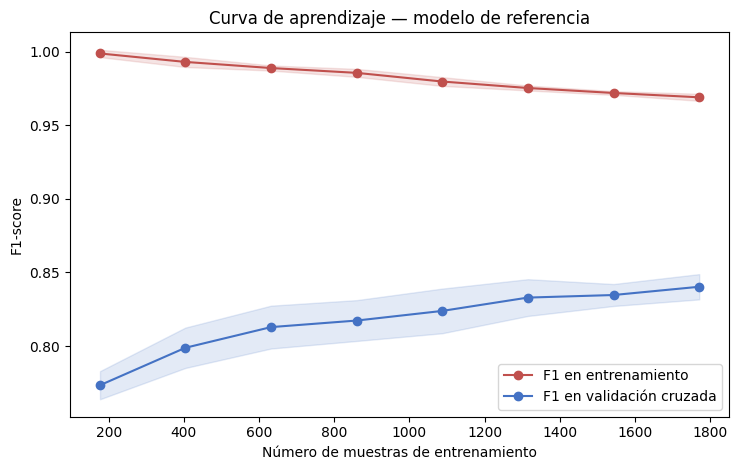


[Figura guardada: curva de aprendizaje]

Con el 80% del train disponible, la brecha train-validación es +0.1287: sobreajuste moderado, esperable en un modelo lineal de alta dimensión como TF-IDF de n-gramas de carácter. La validación sigue subiendo al agregar datos, así que más datos o más regularización (reducir C) podrían ayudar.

=== 1.5 ¿Cuál es la métrica adecuada para este problema de negocio? ===
Matriz de confusión (test):
                 pred_contexto  pred_ataque
  real_contexto            280           51
  real_ataque               70          261

70 falsos negativos (oraciones de ataque reales que el modelo marcó como contexto) y 51 falsos positivos (contexto marcado como ataque) en test.
En un sistema de triage de CTI, un falso negativo es más costoso que un falso positivo: una oración de ataque que pasa como 'contexto' nunca llega a las Etapas 4-7 (vinculación MITRE, severidad, triage) y la oración no entra a la vinculación MITRE; un falso positivo, en cambio, solo le

In [7]:
import os
os.environ["MPLCONFIGDIR"] = "/tmp/mpl-baseline-threatllm"
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.model_selection import learning_curve, StratifiedKFold
import matplotlib

import matplotlib.pyplot as plt

# ---------------------------------------------------------------------------
# 1.1 Pisos ingenuos — ¿qué tan bien le iría a "no aprender nada"?
# ---------------------------------------------------------------------------
print("=== 1.1 Pisos ingenuos (DummyClassifier) — referencia de lo que da el azar ===")
print(
    "Antes de juzgar si un modelo 'funciona', hace falta saber qué tan bien le va a una regla que "
    "no usa ninguna señal del texto. Si el modelo real no supera claramente a estos pisos, el "
    "problema podría ser intrínsecamente difícil o los datos no alcanzar para predecir el objetivo "
    "— exactamente la pregunta que esta fase pide responder."
)

dummy_rows = []
for strategy in ["most_frequent", "stratified", "uniform"]:
    dummy = DummyClassifier(strategy=strategy, random_state=42)
    dummy.fit(train_df["text"], y_train)
    for split_name, df_split, y_split in [("dev", dev_df, y_dev), ("test", test_df, y_test)]:
        y_pred = dummy.predict(df_split["text"])
        y_score = dummy.predict_proba(df_split["text"])[:, 1]
        acc = (y_pred == y_split).mean()
        tp = ((y_pred == 1) & (y_split == 1)).sum()
        fp = ((y_pred == 1) & (y_split == 0)).sum()
        fn = ((y_pred == 0) & (y_split == 1)).sum()
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
        dummy_rows.append({"estrategia": strategy, "split": split_name, "accuracy": round(acc, 4),
                            "precision": round(precision, 4), "recall": round(recall, 4), "f1": round(f1, 4)})

dummy_df = pd.DataFrame(dummy_rows)
print(dummy_df.to_string(index=False))
print(
    "\nInterpretación: con las etiquetas balanceadas 50/50 de sentence_classification, 'most_frequent' "
    "da ~50% de accuracy pero 0 de recall (nunca predice 'ataque'); 'stratified'/'uniform' dan ~50% de "
    "accuracy con F1 también cercano a 0.5. Estos son los pisos reales contra los que se compara "
    "cualquier modelo: cualquier cosa por debajo de ~0.50-0.55 de F1 no estaría aportando señal real."
)

# ---------------------------------------------------------------------------
# 1.2 Modelo de referencia real (ya entrenado en la Etapa 3) vs. los pisos
# ---------------------------------------------------------------------------
print("\n=== 1.2 Modelo de referencia — TF-IDF (n-gramas de caracteres) + LogisticRegression ===")
print(
    "Se elige LogisticRegression sobre TF-IDF como algoritmo de referencia (no un ensamble ni un "
    "modelo profundo) porque cumple exactamente lo que se le pide a un baseline: rápido de entrenar "
    "(segundos, no minutos), determinístico, con coeficientes interpretables término por término "
    "(ver 1.3), y sin hiperparámetros exóticos que ajustar antes de poder evaluarlo. "
    "La configuración (n-gramas de carácter + LogReg) se eligió en la sección 'Selección del algoritmo y características'"
    ", y aquí se entrena solo con sentence_classification (train)."
)

ref_rows = []
for split_name, df_split, y_split in [("train", train_df, y_train), ("dev", dev_df, y_dev), ("test", test_df, y_test)]:
    y_pred = classifier_final.predict(df_split["text"].astype(str))
    y_score = classifier_final.predict_proba(df_split["text"].astype(str))[:, 1]
    m = metric_bundle(y_split, y_pred, y_score)
    ref_rows.append({"split": split_name, **{k: round(v, 4) for k, v in m.items()}})
ref_df = pd.DataFrame(ref_rows)
print(ref_df.to_string(index=False))

floor_f1_test = dummy_df[(dummy_df["split"] == "test") & (dummy_df["estrategia"] == "stratified")]["f1"].iloc[0]
model_f1_test = ref_df[ref_df["split"] == "test"]["f1"].iloc[0]
print(
    f"\nEl modelo de referencia (F1 test={model_f1_test:.4f}) supera por amplio margen al piso "
    f"ingenuo más realista (F1 test≈{floor_f1_test:.4f} con 'stratified'): el problema SÍ contiene "
    "información aprovechable para predecir la etiqueta — no es ruido disfrazado de señal."
)

# ---------------------------------------------------------------------------
# 1.3 Importancia de características
# ---------------------------------------------------------------------------
print("\n=== 1.3 Importancia de características (coeficientes de LogisticRegression) ===")
print(
    "LogisticRegression sobre TF-IDF permite leer la importancia directamente de sus coeficientes: "
    "un coeficiente positivo empuja la predicción hacia 'ataque' (1), uno negativo hacia 'contexto' (0)."
)
clf_step = classifier_final.named_steps["clf"]
tfidf_step = classifier_final.named_steps["tfidf"]
coefs = clf_step.coef_[0]
feat_names = tfidf_step.get_feature_names_out()

order = np.argsort(coefs)
top_neg = order[:15]
top_pos = order[-15:][::-1]

print("\nTop 15 n-gramas de caracteres que más empujan hacia 'ataque' (coeficiente positivo):")
for i in top_pos:
    print(f"  {coefs[i]:+.4f}  {feat_names[i]!r}")

print("\nTop 15 n-gramas de caracteres que más empujan hacia 'contexto' (coeficiente negativo):")
for i in top_neg:
    print(f"  {coefs[i]:+.4f}  {feat_names[i]!r}")

n_irrelevant = int((np.abs(coefs) < 1e-6).sum())
pct_small = (np.abs(coefs) < 0.05).sum() / len(coefs)
print(f"\nCaracterísticas con coeficiente exactamente nulo: {n_irrelevant} de {len(coefs)} "
      f"({n_irrelevant/len(coefs):.1%}).")
print(
      f"Nota: con penalización L2 (Ridge) los coeficientes se encogen pero no llegan a cero, así que '0 características en cero' "
    f"no significa que todas aporten señal. {pct_small:.1%} de los {len(coefs):,} n-gramas tiene un coeficiente menor a 0.05 en magnitud, "
    f"un peso pequeño frente al máximo de ±{np.abs(coefs).max():.1f}; no medimos su efecto conjunto, por lo que no se concluye que sean prescindibles. "
    "Los n-gramas más influyentes parecen reflejar en parte "
    "el estilo de redacción (terminaciones verbales, conectores) además del contenido, por lo que su interpretación debe tomarse con cautela."
)

# ---------------------------------------------------------------------------
# 1.4 Diagnóstico de sub/sobreajuste
# ---------------------------------------------------------------------------
print("\n=== 1.4 ¿El modelo sub/sobreajusta? ===")
train_acc = ref_df[ref_df["split"] == "train"]["accuracy"].iloc[0]
dev_acc = ref_df[ref_df["split"] == "dev"]["accuracy"].iloc[0]
test_acc = ref_df[ref_df["split"] == "test"]["accuracy"].iloc[0]
print(f"Accuracy: train={train_acc:.4f}  dev={dev_acc:.4f}  test={test_acc:.4f}")
print(
    f"\nBrecha train→dev: {train_acc - dev_acc:+.4f} (~{(train_acc - dev_acc)*100:.0f} puntos) entre el "
    f"entrenamiento ({train_acc:.3f}) y dev ({dev_acc:.3f}), que el modelo nunca vio: señal de sobreajuste "
    f"moderado. Dev y test dan resultados parecidos ({dev_acc:.3f} y {test_acc:.3f}), así que la brecha es "
    "consistente y no efecto de una partición difícil. Se confirma con una curva de aprendizaje."
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
train_sizes, train_scores, val_scores = learning_curve(
    make_aux_logreg(), train_df["text"].astype(str), y_train,
    train_sizes=np.linspace(0.1, 1.0, 8), cv=cv, scoring="f1",
    shuffle=True, random_state=42, n_jobs=1,
)
train_mean, train_std = train_scores.mean(axis=1), train_scores.std(axis=1)
val_mean, val_std = val_scores.mean(axis=1), val_scores.std(axis=1)

print("\nCurva de aprendizaje (F1, validación cruzada 5-fold sobre train de sentence_classification):")
curve_df = pd.DataFrame({
    "n_muestras_train": train_sizes,
    "F1_train": train_mean.round(4),
    "F1_val": val_mean.round(4),
    "brecha": (train_mean - val_mean).round(4),
})
print(curve_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.plot(train_sizes, train_mean, marker="o", label="F1 en entrenamiento", color="#C0504D")
ax.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15, color="#C0504D")
ax.plot(train_sizes, val_mean, marker="o", label="F1 en validación cruzada", color="#4472C4")
ax.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.15, color="#4472C4")
ax.set_xlabel("Número de muestras de entrenamiento")
ax.set_ylabel("F1-score")
ax.set_title("Curva de aprendizaje — modelo de referencia")
ax.legend()
plt.tight_layout()
plt.savefig("bl1_curva_aprendizaje.png", dpi=110)
plt.show()
print("\n[Figura guardada: curva de aprendizaje]")

brecha_final = curve_df["brecha"].iloc[-1]
print(
    f"\nCon el 80% del train disponible, la brecha train-validación es {brecha_final:+.4f}: sobreajuste "
    "moderado, esperable en un modelo lineal de alta dimensión como TF-IDF de n-gramas de carácter. "
    "La validación sigue subiendo al agregar datos, así que más datos o más regularización (reducir C) "
    "podrían ayudar."
)

# ---------------------------------------------------------------------------
# 1.5 Métrica adecuada para el problema de negocio
# ---------------------------------------------------------------------------
print("\n=== 1.5 ¿Cuál es la métrica adecuada para este problema de negocio? ===")
y_pred_test = classifier_final.predict(test_df["text"].astype(str))
cm = confusion_matrix(y_test, y_pred_test)
print("Matriz de confusión (test):")
print(f"                 pred_contexto  pred_ataque")
print(f"  real_contexto  {cm[0,0]:>13d}  {cm[0,1]:>11d}")
print(f"  real_ataque    {cm[1,0]:>13d}  {cm[1,1]:>11d}")

fn_test = cm[1, 0]
fp_test = cm[0, 1]
print(
    f"\n{fn_test} falsos negativos (oraciones de ataque reales que el modelo marcó como contexto) y "
    f"{fp_test} falsos positivos (contexto marcado como ataque) en test.\n"
    "En un sistema de triage de CTI, un falso negativo es más costoso que un falso positivo: una oración "
    "de ataque que pasa como 'contexto' nunca llega a las Etapas 4-7 (vinculación MITRE, severidad, "
    "triage) y la oración no entra a la vinculación MITRE; un falso positivo, en cambio, solo le hace revisar "
    "una oración de más. Esto inclina la balanza hacia priorizar RECALL sobre precisión pura — pero "
    "no al extremo de predecir siempre 'ataque' (que maximizaría el recall con tanto ruido que el triage dejaría de ser útil)."
    " Por eso se adopta F1 como métrica principal (porque balancea ambos "
    "errores) y RECALL como métrica secundaria de corte de negocio (porque el costo asimétrico de "
    "los dos tipos de error es real): accuracy sola, usada en el pipeline original como criterio "
    "único, no distingue estos dos tipos de error y con clases balanceadas puede ocultar un recall "
    "mediocre."
)

# ---------------------------------------------------------------------------
# 1.6 Desempeño mínimo aceptable
# ---------------------------------------------------------------------------
print("\n=== 1.6 ¿Cuál debería ser el desempeño mínimo? ===")
UMBRAL_F1 = 0.75
UMBRAL_RECALL = 0.80

print(
    f"Se propone un umbral mínimo explícito, anclado en dos referencias: (a) muy por encima del piso ingenuo "
    f"(F1≈{floor_f1_test:.2f}), para asegurar que el modelo aporta información útil, y (b) la meta de negocio del pipeline heredado "
    f"(accuracy>0.85 en test), que se toma como referencia a superar. Umbral mínimo propuesto: F1 ≥ {UMBRAL_F1:.2f} en test, "
    f"con recall ≥ {UMBRAL_RECALL:.2f} (dado el costo asimétrico de los falsos negativos documentado en 1.5)."
)

f1_real = ref_df[ref_df["split"] == "test"]["f1"].iloc[0]
recall_real = ref_df[ref_df["split"] == "test"]["recall"].iloc[0]
cumple_f1 = f1_real >= UMBRAL_F1
cumple_recall = recall_real >= UMBRAL_RECALL
print(f"\nResultado real del modelo de referencia en test: F1={f1_real:.4f} "
      f"({'cumple' if cumple_f1 else 'NO cumple'} el umbral de {UMBRAL_F1}), "
      f"recall={recall_real:.4f} ({'cumple' if cumple_recall else 'NO cumple'} el umbral de {UMBRAL_RECALL}).")
print(
    "\nConclusión de la Parte 1: el problema de clasificar oraciones ataque/contexto es abordable: "
    f"el baseline supera ampliamente el piso del azar (F1 {f1_real:.2f} vs. ≈{floor_f1_test:.2f}). "
    f"Cumple el umbral de F1, pero {'cumple' if cumple_recall else 'no cumple'} el de recall en test "
    f"({recall_real:.2f} vs. {UMBRAL_RECALL:.2f}), y tampoco alcanza la meta de negocio de accuracy > 0.85 "
    "(se deja como objetivo para los modelos siguientes). El sobreajuste es moderado y deja una "
    "recomendación: regularizar más fuerte (reducir C) o probar otras representaciones antes de pasar "
    "a modelos más complejos."
)


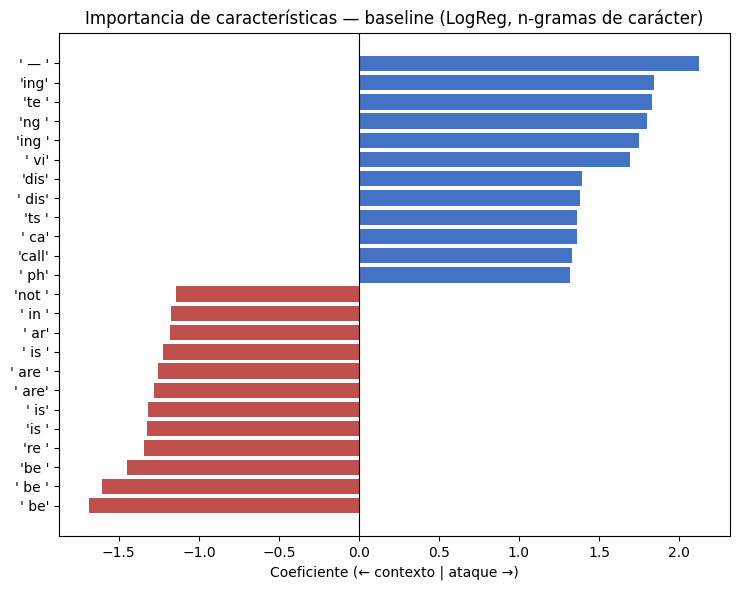

In [8]:
coefs = classifier_final.named_steps["clf"].coef_[0]
nombres = classifier_final.named_steps["tfidf"].get_feature_names_out()
orden = np.argsort(coefs)
idx = np.concatenate([orden[:12], orden[-12:]])          # 12 más hacia "contexto" y 12 más hacia "ataque"

fig, ax = plt.subplots(figsize=(7.5, 6))
colores = ["#C0504D" if coefs[i] < 0 else "#4472C4" for i in idx]
ax.barh([repr(nombres[i]) for i in idx], coefs[idx], color=colores)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Coeficiente (← contexto | ataque →)")
ax.set_title("Importancia de características — baseline (LogReg, n-gramas de carácter)")
plt.tight_layout()
plt.show()

In [9]:
# 1.7 Desempeño en un reporte real (WIRTE/LitePower, Kaspersky) — 96 oraciones con etiqueta de referencia
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

oraciones = pd.read_csv("oraciones_kaspersky.csv")
anot = pd.read_csv("anotacion_referencia.csv")
kasp = oraciones.merge(anot[["id", "label_ref"]], on="id")
kasp = kasp[(kasp["tipo"] == "oracion") & kasp["label_ref"].notna()].copy()
kasp["label_ref"] = kasp["label_ref"].astype(int)
print(f"{len(kasp)} oraciones; etiquetas de referencia (1=ataque): {kasp['label_ref'].value_counts().to_dict()}")

y_real = kasp["label_ref"].to_numpy()
filas = []
for nombre, modelo in [("Baseline (solo SC)", classifier_final), ("Variante reforzada (heredada)", classifier_reforzado)]:
    y_hat = modelo.predict(kasp["texto"].astype(str))
    filas.append({"modelo": nombre,
                  "accuracy": round(accuracy_score(y_real, y_hat), 3),
                  "precision": round(precision_score(y_real, y_hat), 3),
                  "recall": round(recall_score(y_real, y_hat), 3),
                  "f1": round(f1_score(y_real, y_hat), 3)})
display(pd.DataFrame(filas))

cm = confusion_matrix(y_real, classifier_final.predict(kasp["texto"].astype(str)))
print("Matriz de confusión del baseline en el reporte real:")
print(f"  real_contexto: {cm[0,0]} bien, {cm[0,1]} falsos positivos")
print(f"  real_ataque:   {cm[1,1]} bien, {cm[1,0]} falsos negativos")

96 oraciones; etiquetas de referencia (1=ataque): {1: 55, 0: 41}


,modelo,accuracy,precision,recall,f1
0,Baseline (solo SC),0.604,0.870,0.364,0.513
1,Variante reforzada (heredada),0.583,0.895,0.309,0.459


Matriz de confusión del baseline en el reporte real:
  real_contexto: 38 bien, 3 falsos positivos
  real_ataque:   20 bien, 35 falsos negativos


**Desempeño en un reporte real**

Se evaluó el baseline sobre las 96 oraciones del reporte WIRTE/LitePower de Kaspersky, con etiquetas de referencia manuales incluidas en el análisis del asesor, quien recomienda revisarlas (véase el anexo 1).

El modelo casi no se equivoca cuando marca "ataque" (precisión alta, 3 falsos positivos), pero deja pasar la mayoría de las oraciones de ataque (recall ≈ 0.36).

Es decir, el desempeño dentro de LADDER (F1 ≈ 0.81) no se traslada a un reporte real. Esto es compatible con un cambio de dominio: ninguna oración de train contiene términos típicos del reporte como powershell, registry o vbs (véase el anexo 2).

Por ello, ni el umbral de recall ni la meta de negocio se cumplen en el reporte real, y mejorar la generalización es el objetivo de los modelos siguientes.

Este resultado ilustra una limitación ya señalada en el Avance 2 (sesgo de corpus: el vocabulario de LADDER refleja malware móvil y puede no generalizar a otros tipos de ataque).

**Síntesis de la Parte 1**

El piso ingenuo más realista (`DummyClassifier(strategy="stratified")`) da F1≈0.48 en test.

El modelo de referencia (baseline) es TF-IDF de n-gramas de carácter + LogisticRegression entrenado solo con sentence_classification (seleccionado en la sección inicial del notebook).

Obtiene F1=0.812 en test (0.821 en dev), muy por encima del piso: **el problema es abordable dentro de LADDER**. Los coeficientes permiten leer la importancia de las características: n-gramas como `' — '` (la raya, el de mayor peso), `'ing'`, `' vi'` o `' dis'` empujan hacia "ataque" y `' be'`, `'is '` o `'not '` hacia "contexto"; parecen reflejar en parte el estilo de redacción (terminaciones verbales, conectores) además del contenido, algo que habría que confirmar.

Hay sobreajuste moderado: brecha train–dev de 0.15 (en accuracy) y brecha train–validación de 0.13 (en F1) con el 80 % del train (1771 oraciones), con la validación aún mejorando al agregar datos.

Se justifica F1 como métrica principal y recall como secundaria, porque un falso negativo es más costoso que un falso positivo.

Como el falso negativo cuesta más, en el Avance 4 se evaluará F2 o un ajuste del umbral sobre dev (nunca sobre las 96 oraciones del reporte), para priorizar recall con una precisión mínima.

 El baseline cumple el umbral de F1 (≥ 0.75), pero el recall en test (0.789) queda ligeramente por debajo de 0.80 y la accuracy (0.817) no alcanza la meta de negocio de 0.85; ambos se dejan como referencia a superar. Estos resultados son dentro de LADDER.

 La referencia histórica (variante reforzada heredada) y los umbrales propios se discuten en la Parte 3, pregunta 5.

En un reporte real (96 oraciones de Kaspersky), el recall cae a ≈ 0.36 (sección 1.7), por lo que el desempeño en LADDER no se traslada directamente.

# Parte 2 | Baseline para el problema secundario: clasificación de técnica MITRE

`attack-pattern-matching-gt.csv` (versión corregida por el equipo: 81 descripciones de procedimiento, 32 técnicas, 10 de una sola muestra) no tiene splits oficiales train/dev/test, a diferencia de `sentence_classification`. Esta diferencia estructural ya es la primera pista de que el baseline aquí se comporta distinto.

=== 2.1 Piso ingenuo — clasificación de técnica MITRE (attack-pattern-matching-gt) ===
A diferencia de sentence_classification, este dataset NO tiene splits oficiales train/dev/test — LADDER lo publica como un único corpus de referencia de 81 filas. Eso ya es la primera señal de que un baseline supervisado aquí es distinto en naturaleza al de la Parte 1.

81 muestras, 32 clases (técnicas) distintas, 10 de ellas con una sola muestra en todo el dataset.

Piso 'most_frequent': predecir siempre 'T1417' (la técnica más común, 7 de 81 filas) da accuracy=0.0864 (8.6%).
Piso 'stratified' (muestreo aleatorio según la frecuencia real de cada técnica, promedio de 2000 simulaciones): accuracy≈0.0433 (4.3%) — equivalente analíticamente a sum(p_i^2) sobre las 32 clases.

=== 2.2 Intento de modelo de referencia supervisado (Leave-One-Out) ===
Con 10 de 32 clases teniendo una sola muestra, la partición estratificada no puede aplicarse bien (train_test_split con stratify falla y StratifiedKFold solo em

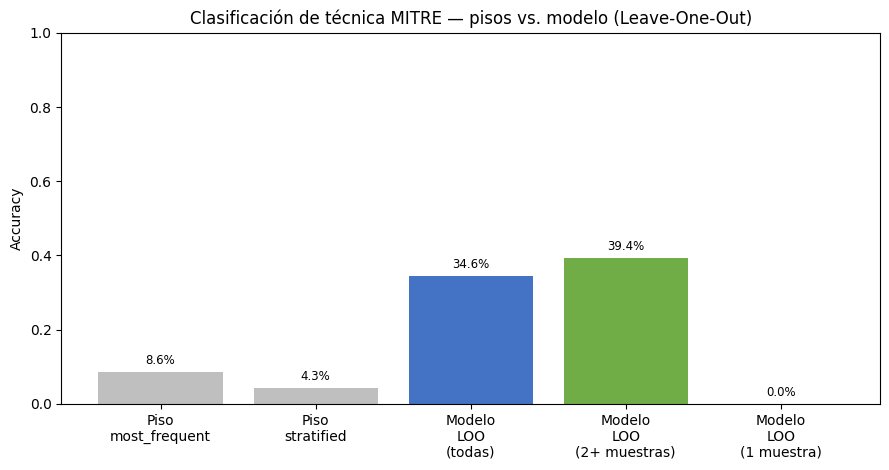


[Figura guardada: comparación de accuracy entre pisos y modelo, con desglose singleton]

=== 2.3 Conclusión — viabilidad de este problema secundario ===
Este NO es un problema viable como clasificador supervisado con los datos actuales: 81 muestras para 32 clases (menos de 3 ejemplos por clase en promedio, y 10 clases con un solo ejemplo) es insuficiente; con tan pocos datos no es posible separar el efecto del algoritmo. La similitud (Etapa 4) no requiere entrenar un clasificador, pero solo puede devolver técnicas presentes en el corpus de referencia (como máximo 5 de las 18 del reporte, véase 2.4); su evaluación contra las 18 TTPs queda pendiente.


In [10]:
import os
os.environ["MPLCONFIGDIR"] = "/tmp/mpl-baseline-threatllm"
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import accuracy_score, f1_score
import matplotlib

import matplotlib.pyplot as plt


def _find_base(*relative_candidates):
    here = Path.cwd()
    search_roots = [here] + list(here.parents)[:4]
    for base in search_roots:
        for rel in relative_candidates:
            p = base / rel
            if p.exists():
                return p
    raise FileNotFoundError(f"No se encontró ninguna de estas rutas relativas a {here}: {relative_candidates}")


AP_PATH = _find_base("data/attack_pattern/attack-pattern-matching-gt.csv")
ap_df = pd.read_csv(AP_PATH)

print("=== 2.1 Piso ingenuo — clasificación de técnica MITRE (attack-pattern-matching-gt) ===")
print(
    "A diferencia de sentence_classification, este dataset NO tiene splits oficiales train/dev/test "
    "— LADDER lo publica como un único corpus de referencia de 81 filas. Eso ya es la primera señal "
    "de que un baseline supervisado aquí es distinto en naturaleza al de la Parte 1."
)
n_total = len(ap_df)
n_classes = ap_df["label"].nunique()
label_counts = ap_df["label"].value_counts()
n_singleton = (label_counts == 1).sum()
print(f"\n{n_total} muestras, {n_classes} clases (técnicas) distintas, {n_singleton} de ellas con una "
      f"sola muestra en todo el dataset.")

most_frequent_label = label_counts.idxmax()
most_frequent_count = label_counts.max()
dummy_acc = most_frequent_count / n_total
print(f"\nPiso 'most_frequent': predecir siempre '{most_frequent_label}' (la técnica más común, "
      f"{most_frequent_count} de {n_total} filas) da accuracy={dummy_acc:.4f} ({dummy_acc:.1%}).")

rng = np.random.default_rng(42)
probs = (label_counts / n_total).to_dict()
n_sim = 2000
stratified_accs = []
for _ in range(n_sim):
    sim_pred = rng.choice(list(probs.keys()), size=n_total, p=list(probs.values()))
    stratified_accs.append((sim_pred == ap_df["label"].to_numpy()).mean())
print(f"Piso 'stratified' (muestreo aleatorio según la frecuencia real de cada técnica, promedio de "
      f"{n_sim} simulaciones): accuracy≈{np.mean(stratified_accs):.4f} "
      f"({np.mean(stratified_accs):.1%}) — equivalente analíticamente a sum(p_i^2) sobre las 32 clases.")

# ---------------------------------------------------------------------------
# 2.2 Intento de modelo de referencia supervisado — Leave-One-Out
# ---------------------------------------------------------------------------
print("\n=== 2.2 Intento de modelo de referencia supervisado (Leave-One-Out) ===")
print(
    "Con 10 de 32 clases teniendo una sola muestra, la partición estratificada no puede aplicarse bien "
    "(train_test_split con stratify falla y StratifiedKFold solo emite una advertencia). "
    "Se usa Leave-One-Out (LOO) porque aprovecha todas las filas. "
    "En cada iteración se deja 1 fila fuera como prueba y se "
    "entrena con las 80 restantes, pero esto significa que, para las 10 técnicas de una sola "
    "muestra, el modelo nunca ve un ejemplo de esa clase durante el entrenamiento de su propia "
    "iteración de prueba: es estructuralmente imposible que las prediga bien, y eso es, en sí mismo, "
    "el resultado relevante para esta fase, no un error del experimento."
)

X_text = ap_df["text"].astype(str)
y = ap_df["label"].to_numpy()

loo = LeaveOneOut()
y_pred_loo = np.empty(n_total, dtype=object)
for train_idx, test_idx in loo.split(X_text):
    vec = TfidfVectorizer(ngram_range=(1, 2), min_df=1, sublinear_tf=True)
    X_train_loo = vec.fit_transform(X_text.iloc[train_idx])
    X_test_loo = vec.transform(X_text.iloc[test_idx])
    clf = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42)
    clf.fit(X_train_loo, y[train_idx])
    y_pred_loo[test_idx] = clf.predict(X_test_loo)

acc_loo = accuracy_score(y, y_pred_loo)
f1_macro_loo = f1_score(y, y_pred_loo, average="macro", zero_division=0)
f1_weighted_loo = f1_score(y, y_pred_loo, average="weighted", zero_division=0)
print(f"\nResultado LOO (81 iteraciones, TF-IDF + LogisticRegression multinomial):")
print(f"  accuracy          = {acc_loo:.4f} ({acc_loo:.1%})")
print(f"  F1 macro          = {f1_macro_loo:.4f}  (promedia las 32 clases por igual, penaliza fuerte no acertar las raras)")
print(f"  F1 weighted       = {f1_weighted_loo:.4f}  (pondera por frecuencia real de cada clase)")

singleton_labels = label_counts[label_counts == 1].index.tolist()
singleton_mask = ap_df["label"].isin(singleton_labels).to_numpy()
acc_singleton = accuracy_score(y[singleton_mask], y_pred_loo[singleton_mask])
acc_non_singleton = accuracy_score(y[~singleton_mask], y_pred_loo[~singleton_mask])
print(f"\nAccuracy LOO solo en las {singleton_mask.sum()} filas de técnicas de una sola muestra: "
      f"{acc_singleton:.4f} ({acc_singleton:.1%}).")
print(f"Accuracy LOO en las {(~singleton_mask).sum()} filas de técnicas con 2+ muestras: "
      f"{acc_non_singleton:.4f} ({acc_non_singleton:.1%}).")

comparacion = pd.DataFrame([
    {"Enfoque": "Piso most_frequent", "accuracy": round(dummy_acc, 4)},
    {"Enfoque": "Piso stratified (simulado)", "accuracy": round(float(np.mean(stratified_accs)), 4)},
    {"Enfoque": "TF-IDF + LogisticRegression (LOO)", "accuracy": round(acc_loo, 4)},
])
print("\nComparación resumida:")
print(comparacion.to_string(index=False))
print(
    f"\nEl modelo supervisado (accuracy={acc_loo:.1%}) SÍ supera a los pisos ingenuos "
    f"({dummy_acc:.1%} / {np.mean(stratified_accs):.1%}), lo que indica que el texto de las 71 "
    "filas con 2+ muestras sí contiene algo de señal aprovechable. Pero la accuracy absoluta "
    "sigue siendo baja para un sistema de producción, y el desglose por grupo es la evidencia clave: "
    f"el modelo acierta {acc_non_singleton:.1%} en técnicas con suficientes ejemplos, pero solo "
    f"{acc_singleton:.1%} en las de una sola muestra, consistente con lo que anticipa esa "
    "restricción."
)

fig, ax = plt.subplots(figsize=(9, 4.8))
bars = ax.bar(["Piso\nmost_frequent", "Piso\nstratified", "Modelo\nLOO\n(todas)",
               "Modelo\nLOO\n(2+ muestras)", "Modelo\nLOO\n(1 muestra)"],
              [dummy_acc, np.mean(stratified_accs), acc_loo, acc_non_singleton, acc_singleton],
              color=["#BFBFBF", "#BFBFBF", "#4472C4", "#70AD47", "#C0504D"])
ax.set_ylabel("Accuracy")
ax.set_title("Clasificación de técnica MITRE — pisos vs. modelo (Leave-One-Out)")
ax.set_ylim(0, 1)
for b in bars:
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.02, f"{b.get_height():.1%}",
            ha="center", fontsize=8.5)
plt.tight_layout()
plt.savefig("bl2_attack_pattern_baseline.png", dpi=110)
plt.show()
print("\n[Figura guardada: comparación de accuracy entre pisos y modelo, con desglose singleton]")

# ---------------------------------------------------------------------------
# 2.3 Conclusión de la Parte 2
# ---------------------------------------------------------------------------
print("\n=== 2.3 Conclusión — viabilidad de este problema secundario ===")
print(
    "Este NO es un problema viable como clasificador supervisado con los datos actuales: 81 muestras "
    "para 32 clases (menos de 3 ejemplos por clase en promedio, y 10 clases con un solo ejemplo) es "
    "insuficiente; con tan pocos datos no es posible separar el efecto del algoritmo. "
    "La similitud (Etapa 4) no requiere entrenar un clasificador, pero solo puede devolver técnicas presentes en el corpus de referencia "
    "(como máximo 5 de las 18 del reporte, véase 2.4); su evaluación contra las 18 TTPs queda pendiente."
)


In [11]:
# 2.4 Desajuste de catálogo: Mobile (corpus) vs Enterprise (reporte)
import json
ttps_reporte = {   # 18 técnicas del ground truth del reporte (Enterprise) y su nombre oficial
 "T1007":"System Service Discovery","T1012":"Query Registry","T1033":"System Owner/User Discovery",
 "T1041":"Exfiltration Over C2 Channel","T1053":"Scheduled Task/Job","T1059":"Command and Scripting Interpreter",
 "T1071":"Application Layer Protocol","T1082":"System Information Discovery","T1105":"Ingress Tool Transfer",
 "T1106":"Native API","T1112":"Modify Registry","T1113":"Screen Capture","T1518":"Software Discovery",
 "T1547":"Boot or Logon Autostart Execution","T1564":"Hide Artifacts","T1574":"Hijack Execution Flow",
 "T1588":"Obtain Capabilities","T1598":"Phishing for Information",
}
nombres_mobile = json.load(open(_find_base("data/mitre/mobile_attack_techniques.json")))
ids_corpus = sorted(ap_df["label"].unique())
mobile_por_nombre = {nombres_mobile[i].lower(): i for i in ids_corpus if i in nombres_mobile}

inter_ids = sorted(set(ids_corpus) & set(ttps_reporte))
print(f"Intersección por ID: {len(inter_ids)} de {len(ttps_reporte)}")

equiv = [(e, n, mobile_por_nombre[n.lower()]) for e, n in ttps_reporte.items() if n.lower() in mobile_por_nombre]
print(f"Intersección por nombre: {len(equiv)} de {len(ttps_reporte)}")
for e, n, m in equiv:
    print(f"   Enterprise {e} = Mobile {m}  ({n})")
print(f"Sin contraparte en el corpus: {len(ttps_reporte) - len(equiv)} de {len(ttps_reporte)}")

Intersección por ID: 0 de 18
Intersección por nombre: 5 de 18
   Enterprise T1041 = Mobile T1646  (Exfiltration Over C2 Channel)
   Enterprise T1059 = Mobile T1623  (Command and Scripting Interpreter)
   Enterprise T1113 = Mobile T1513  (Screen Capture)
   Enterprise T1518 = Mobile T1418  (Software Discovery)
   Enterprise T1564 = Mobile T1628  (Hide Artifacts)
Sin contraparte en el corpus: 13 de 18


In [12]:
mobile_todos = {n.lower(): i for i, n in nombres_mobile.items()}
en_catalogo = {e: mobile_todos[n.lower()] for e, n in ttps_reporte.items() if n.lower() in mobile_todos}
fuera_corpus = {e: m for e, m in en_catalogo.items() if m not in ids_corpus}
print(len(en_catalogo), "de", len(ttps_reporte), "tienen equivalente por nombre en el catálogo Mobile")
print(len(fuera_corpus), "están en el catálogo Mobile pero no en el corpus:", fuera_corpus)
print(len(ttps_reporte) - len(en_catalogo), "solo existen en Enterprise")

11 de 18 tienen equivalente por nombre en el catálogo Mobile
6 están en el catálogo Mobile pero no en el corpus: {'T1053': 'T1603', 'T1071': 'T1437', 'T1082': 'T1426', 'T1105': 'T1544', 'T1106': 'T1575', 'T1574': 'T1625'}
7 solo existen en Enterprise


**Síntesis de la Parte 2**

Con 10 de 32 clases con una sola muestra, no puede aplicarse bien el estratificar la validación (una clase de una sola muestra no puede estar a la vez en entrenamiento y en validación), así que se usó Leave-One-Out.

El resultado es exactamente el que esa restricción predice: el modelo de referencia (TF-IDF + LogisticRegression bajo LOO) obtiene 34.6% de accuracy global — por encima de los pisos ingenuos (8.6% / 4.3%), así que el texto sí aporta algo de señal — pero esa señal se concentra enteramente en las 71 filas de técnicas con
2+ muestras (39.4% de accuracy ahí) y es **estructuralmente 0% en las 10 filas de técnicas de una
sola muestra**.


Es consistente con que el problema, con 81 muestras para 32 clases, no tiene datos suficientes para ser resuelto como clasificación supervisada (el 0 % en clases de una sola muestra es inevitable por construcción del LOO; la evidencia real es el 39.4 % en las clases con 2 o más muestras).

La similitud (Etapa 4) no requiere entrenar un clasificador, pero solo puede devolver técnicas presentes en el corpus de referencia (como máximo 5 de las 18 del reporte, véase 2.4); su evaluación contra las 18 TTPs queda pendiente.

**Una segunda limitación, independiente de la primera.** La escasez de datos por clase no es la única razón por la que un clasificador supervisado de técnicas no es viable aquí. `attack-pattern-matching-gt` está construido enteramente con malware **móvil** (Ginp, Cerberus, DualToy, SpyDealer...) y usa identificadores de la matriz **ATT&CK Mobile**, mientras que el reporte de referencia WIRTE/LitePower está catalogado por MITRE como software para **Windows** (S0680) y su ground truth usa identificadores de la matriz **ATT&CK Enterprise**: catálogos distintos.

Por ID, la intersección es de 0 de 18, pero esa cifra es en parte un artefacto de numeraciones distintas. Por nombre de técnica, 5 de las 18 (Command and Scripting Interpreter, Exfiltration Over C2 Channel, Screen Capture, Software Discovery y Hide Artifacts) tienen contraparte con otro ID en el corpus Mobile; las otras 13 no tienen ninguna en el corpus. Por ello, un modelo entrenado solo con este corpus cubriría como máximo 5 de las 18 técnicas del reporte, aun con más muestras por clase; para cubrir las demás hace falta ampliar el corpus: 6 tienen equivalente en la matriz Mobile (por ejemplo, Scheduled Task/Job o Native API) y otras 7 (por ejemplo, Query Registry o Modify Registry) solo existen en Enterprise.

Ambas limitaciones son independientes y deben resolverse por separado: la primera con más datos etiquetados por técnica, la segunda con un corpus construido específicamente en la matriz Enterprise.

# Parte 3 | Conclusiones de la fase de baseline, respondiendo las preguntas guía

### 1. ¿Qué algoritmo se puede utilizar como baseline?

Para el problema principal se eligió **TF-IDF de n-gramas de carácter + LogisticRegression**, seleccionado entre 5 candidatos y un piso (Dummy) comparados en validación cruzada y dev (sección inicial del notebook). Para el secundario se usó TF-IDF de palabras + LogisticRegression bajo Leave-One-Out, limitado por los datos disponibles.


### 2. ¿Se puede determinar la importancia de las características?

Sí, con un método embedded: los coeficientes de la regresión logística con penalización L2, que se aprenden durante el ajuste (gráfica en 1.3). Es un análisis de relevancia, no una selección: ningún coeficiente es exactamente cero y el 45.7 % de los 63 316 n-gramas tiene peso menor a 0.05. El n-grama con más peso hacia “ataque” es la raya ‘ — ‘ (+2.13), un rasgo tipográfico y no de contenido, lo que sugiere que parte de la señal puede ser un artefacto del corpus.

En la Parte 2, la importancia de características es secundaria frente al hallazgo principal: con tan pocos datos por clase, ningún análisis de importancia sería confiable.


### 3. ¿El modelo está sub/sobreajustando los datos de entrenamiento?

Problema principal --> sobreajuste **moderado**: accuracy de 0.965 en train contra 0.815 en dev (brecha de 0.15), y brecha train-validación de 0.13 en la curva de aprendizaje, con la validación aún mejorando al agregar datos.

Problema secundario --> no aplica un diagnóstico de sub/sobreajuste en el sentido habitual, pues es un problema de **datos insuficientes** (el modelo no puede ver 10 de las 32 clases durante el entrenamiento de su propia evaluación).

### 4. ¿Cuál es la métrica adecuada para este problema de negocio?

Problema principal: **F1** como métrica principal (balancea falsos positivos y negativos) y
**recall** como métrica secundaria de corte de negocio, porque en un sistema de triage de CTI un
falso negativo (oración de ataque no detectada, que nunca llega a las Etapas 4-7) es más costoso
que un falso positivo (una oración de más para revisar). Accuracy sola, usada originalmente como
único criterio en el pipeline, no distingue estos dos tipos de error.

Problema secundario: accuracy
desglosada por grupo (técnicas con 2+ muestras vs. de una sola muestra) es más informativa que
cualquier métrica agregada, porque el agregado esconde el patrón real.

### 5. ¿Cuál debería ser el desempeño mínimo a obtener?

Problema principal: existe una referencia histórica, la variante reforzada del pipeline heredado (accuracy 0.858, recall 0.852 y F1 0.857 en test), pero no es comparable directamente (otra composición de entrenamiento y filtro contra test solo por coincidencia exacta) y en el reporte real rinde peor que el baseline (recall 0.309 vs 0.364). Por eso se fija un umbral propio: F1 ≥ 0.75, como margen claro sobre el piso ingenuo (F1 ≈ 0.48), y recall ≥ 0.80, por el costo asimétrico de los falsos negativos; la meta heredada (accuracy > 0.85) queda como referencia a superar.

Problema secundario: no es posible fijar aún un umbral de desempeño mínimo. El baseline actual (clasificador con LOO) obtiene 34.6 % de accuracy global y 0 % en técnicas de una sola muestra, y la similitud coseno de la Etapa 4 no se ha evaluado formalmente contra las 18 TTPs del reporte.

Con el corpus actual (Mobile), esa evaluación por IDs daría 0 aciertos por el desajuste de catálogo (Parte 2, sección 2.4).

Antes de fijar un umbral se necesita (a) un corpus de referencia en la matriz Enterprise y (b) si el enfoque pasa a ser de recuperación de varias técnicas por oración, una métrica de ese tipo, por ejemplo recall@k, en vez de accuracy.

### Conclusión general y marco de referencia para modelos más avanzados

El baseline cumple el objetivo 3.2 de esta fase: da una referencia cuantitativa (F1 = 0.812 y recall = 0.789 en test de LADDER; F1 ≈ 0.51 y recall ≈ 0.36 en el reporte real) contra la cual cualquier modelo más avanzado debe demostrar una mejora, sobre todo en el reporte real.

Para la vinculación con técnicas MITRE, el baseline sugiere que, además de la escasez de datos por clase, el corpus disponible (Mobile) cubre como máximo 5 de las 18 técnicas del reporte de referencia (Enterprise), por lo que se requiere un corpus Enterprise antes de invertir en un clasificador supervisado más complejo.

# Parte 4 | Limitaciones y trabajo siguiente



**Decisión sobre los datos de entrenamiento.** El corpus attack-pattern-matching-gt contiene técnicas de ATT&CK Mobile, mientras que el reporte de referencia (WIRTE/LitePower) corresponde a técnicas Enterprise (intersección de 0 de 18 por ID, 5 de 18 por nombre, véase 2.4). Por ello, este corpus no se usa para entrenar un clasificador de técnicas aplicable al reporte; se conserva como referencia de evaluación y de similitud, con esa limitación declarada.

Si el cliente elige ampliar los datos (véase «Decisión pendiente con el cliente»), el siguiente paso sería construir ese corpus a partir de los ejemplos de procedimiento que MITRE publica por técnica, incluyendo también las técnicas que ya existen en Mobile y no están en el corpus actual.

**Limitaciones del baseline.**
- Los resultados de F1 ≈ 0.81 son dentro de LADDER. En el reporte real el recall cae a ≈ 0.36, lo que es compatible con un cambio de dominio ( ninguna oración de train contiene términos como powershell, registry o vbs; véase anexo 2).
- Las etiquetas de las 96 oraciones del reporte son una anotación manual de referencia, incluida en el análisis del asesor, quien recomienda revisarla (véase anexo 1).
- Dev se usó para seleccionar el modelo; la única partición no usada en la selección es test.
- El sobreajuste es moderado (brecha train–validación ≈ 0.13).
- Los n-gramas más influyentes parecen reflejar en parte el estilo de redacción y no solo el contenido, algo que debe confirmarse.
- El set reforzado heredado del pipeline se descartó como baseline y se conserva solo como comparación heredada porque su composición difiere de la del conjunto original.

La conclusión se sostiene aun con algunos errores de etiquetado: para que el recall del baseline llegara a 0.80, habría que reetiquetar como "contexto" 30 de las 35 oraciones de ataque que el modelo dejó pasar.

**Trabajo siguiente.**
1. Probar embeddings (sentence-transformers o SecBERT) para filtrar oraciones y compararlas con las descripciones de ATT&CK.
2. Probar un LLM con la lista oficial de técnicas, exigiendo una frase de evidencia por técnica y validando los IDs devueltos; considerar la contaminación (el reporte es público desde 2021) y validar también con reportes posteriores.
3. Comparar TF-IDF, embeddings y LLM sobre las mismas 96 oraciones y 18 TTPs, para justificar la elección con números.
4. Regularizar más fuerte (reducir C).
5. Validar los pesos de la CTS (Composite Threat Score) heurísticos
6. Evaluar el baseline en un reporte del dominio móvil (el de LADDER) etiquetado manualmente, para separar con datos el efecto del cambio de dominio del de la calidad del modelo.

## **Decisión pendiente con el cliente**

El corpus de entrenamiento corresponde a ATT&CK Mobile y el reporte de referencia a técnicas Enterprise (intersección de 0 de 18 por ID y 5 de 18 por nombre, véase 2.4).

Para el siguiente avance, el equipo propone consultar al cliente cuál de las dos rutas prefiere: (a) ampliar los datos de entrenamiento con ejemplos de técnicas Enterprise, o (b) cambiar el tipo de entrada, es decir, evaluar con reportes del dominio móvil.

Esta decisión depende de los objetivos del cliente, por lo que se considera pertinente someterla a su criterio.


---

Esta fase establece el baseline y sus límites.

Los datos Enterprise exigen construir y etiquetar un corpus nuevo, y esa decisión de alcance depende del cliente. Por eso se documenta, cuantifica y se propone consultarlo con el cliente.

# Anexo

## 1. Revisión de las etiquetas del reporte (parcial)

**Revisión de las etiquetas (38 oraciones en desacuerdo).**

Se examinaron las 38 oraciones donde el baseline y la anotación del asesor discrepan, con dos revisiones: una primera, con la predicción del modelo a la vista, y una segunda ciega (solo id y texto).

La primera coincide con el asesor en 31 oraciones (3 ambiguas, 4 discrepan); la segunda, en 23 (4 ambiguas, 11 discrepan).

Entre ambos revisores coinciden en 19 de 32 oraciones comparables, lo que sugiere que el criterio ataque/contexto es subjetivo en este tipo de oraciones (por ejemplo, en los pasos numerados de una macro).

Aun así, el recall del baseline en el reporte real pasa de 0.36 (etiquetas del asesor) a 0.40 o 0.45 según la revisión, muy por debajo del umbral de 0.80, por lo que el recall no depende de los errores de etiquetado: la caída es compatible con un cambio de dominio (hipótesis que se evaluaría con el punto 6 del trabajo siguiente).


La revisión es parcial (no incluye los 58 aciertos), por lo que no sustituye una reanotación completa del reporte.


In [13]:
# Predicciones del baseline sobre las 96 oraciones del reporte de Kaspersky
kasp["pred"] = classifier_final.predict(kasp["texto"].astype(str))
kasp["prob_ataque"] = classifier_final.predict_proba(kasp["texto"].astype(str))[:, 1].round(3)

# Oraciones en desacuerdo: el modelo predice distinto a la etiqueta del asesor (label_ref)
revisar = kasp[kasp["pred"] != kasp["label_ref"]].copy()

# Tipo de error: FN = el asesor dijo ataque y el modelo contexto; FP = al revés
revisar["tipo_error"] = revisar.apply(
    lambda r: "FN (el modelo dijo contexto)" if r["label_ref"] == 1 else "FP (el modelo dijo ataque)", axis=1)

# Se ordena por tipo de error y por id, y se guardan solo las columnas útiles
revisar = revisar[["id", "tipo_error", "label_ref", "prob_ataque", "texto"]].sort_values(["tipo_error", "id"])
print(len(revisar), revisar["tipo_error"].value_counts().to_dict())   # esperado: 38 {FN: 35, FP: 3}
revisar.to_csv("oraciones_a_revisar.csv", index=False)

# Se muestran completas las oraciones para poder leerlas
pd.set_option("display.max_colwidth", None)
display(revisar)

38 {'FN (el modelo dijo contexto)': 35, 'FP (el modelo dijo ataque)': 3}


,id,tipo_error,label_ref,prob_ataque,texto
0,K003,FN (el modelo dijo contexto),1,0.313,"This February, during our hunting efforts for threat actors using VBS/VBA implants, we came across MS Excel droppers that use hidden spreadsheets and VBA macros to drop their first stage implant."
11,K016,FN (el modelo dijo contexto),1,0.203,The Word droppers were using standard VBA macros to download the payload.
12,K017,FN (el modelo dijo contexto),1,0.418,"The actor tailored the decoy contents to the targeted victims, using logos and themes relevant to the targeted company or using trending topics from their region and, in one instance, even mimicking the Palestinian authority."
13,K018,FN (el modelo dijo contexto),1,0.238,"However, in some cases we saw a fake ‘Kaspersky Update Agent’ executable acting as a dropper for the VBS implant."
14,K019,FN (el modelo dijo contexto),1,0.239,"We were unable to confirm if this PE file was also distributed through email or downloaded by the threat actor after some initial penetration, but our analysis shows it has the same execution flow as the Excel 4.0 macros."
15,K023,FN (el modelo dijo contexto),1,0.257,This first stage implant is composed of VBS and PowerShell scripts.
20,K028,FN (el modelo dijo contexto),1,0.477,The dropper will then run formulas from a third spreadsheet with hidden columns.
22,K030,FN (el modelo dijo contexto),1,0.333,"1: Get the name of the environment in which Microsoft Excel is running, as text, followed by the environment’s version number."
23,K031,FN (el modelo dijo contexto),1,0.352,"The result will then be compared to a predefined Windows version in a hidden cell, for example: Windows (64-bit) NT :.00, Windows (64-bit) NT 6.01, Windows (32-bit) NT 10.00, Windows (32-bit) NT 6.02."
24,K032,FN (el modelo dijo contexto),1,0.254,19: Check if a mouse is present.


In [14]:
# Revisión de las 38 oraciones en desacuerdo

# Etiquetas del equipo por id de oración: 1 = ataque, 0 = contexto, "?" = ambigua
team_etiquetas = {
 "K003":1,"K016":1,"K017":1,"K018":1,"K019":"?","K023":1,"K028":1,"K030":1,"K031":1,"K032":1,
 "K033":1,"K034":1,"K036":1,"K038":1,"K040":1,"K041":1,"K044":1,"K047":1,"K048":1,"K049":1,
 "K050":1,"K063":1,"K064":1,"K092":1,"K098":1,"K104":1,"K106":1,"K107":1,"K108":1,"K112":"?",
 "K113":1,"K114":0,"K115":1,"K116":"?","K128":1,"K024":1,"K042":1,"K096":1,
}

# Se compara la etiqueta del equipo con la del asesor: coincide, discrepa o ambigua
rev = revisar.copy()
rev["etiqueta_equipo"] = rev["id"].map(team_etiquetas)
rev["resultado"] = [
    "ambigua" if m == "?" else ("coincide" if int(m) == int(l) else "discrepa")
    for m, l in zip(rev["etiqueta_equipo"], rev["label_ref"])
]
print(rev["resultado"].value_counts().to_string())

# Sensibilidad: cómo cambian las métricas si se adoptan las correcciones del equipo
# (las ambiguas y las no revisadas conservan la etiqueta original del asesor)
from sklearn.metrics import precision_score, recall_score, f1_score
nueva = kasp["id"].map(team_etiquetas)
kasp["label_rev"] = [int(n) if n in (0, 1) else l for n, l in zip(nueva, kasp["label_ref"])]
for nombre, col in [("Etiquetas del asesor", "label_ref"), ("Tras revisión", "label_rev")]:
    print(f"{nombre}: precision={precision_score(kasp[col], kasp['pred']):.3f}  "
          f"recall={recall_score(kasp[col], kasp['pred']):.3f}  F1={f1_score(kasp[col], kasp['pred']):.3f}")

resultado
coincide    31
discrepa     4
ambigua      3
Etiquetas del asesor: precision=0.870  recall=0.364  F1=0.513
Tras revisión: precision=1.000  recall=0.404  F1=0.575


In [15]:
# Segunda revisión (ciega: solo id y texto). '?' = ambigua
irv_etiquetas = {
 "K003":1,"K016":1,"K017":0,"K018":1,"K019":"?","K023":0,"K028":"?","K030":0,"K031":0,"K032":0,
 "K033":0,"K034":0,"K036":0,"K038":1,"K040":1,"K041":1,"K044":1,"K047":1,"K048":1,"K049":1,
 "K050":0,"K063":0,"K064":"?","K092":1,"K098":1,"K104":1,"K106":1,"K107":1,"K108":1,"K112":1,
 "K113":1,"K114":1,"K115":1,"K116":0,"K128":1,"K024":0,"K042":"?","K096":0,
}

def resumen(d, nombre):
    est = ["ambigua" if str(d[i]) == "?" else ("coincide" if int(d[i]) == int(l) else "discrepa")
           for i, l in zip(revisar["id"], revisar["label_ref"])]
    print(nombre, pd.Series(est).value_counts().to_dict())

resumen(team_etiquetas, "Revisión 1 (con predicción visible):")
resumen(irv_etiquetas, "Revisión 2 (ciega):")

comunes = [i for i in revisar["id"] if str(team_etiquetas[i]) != "?" and str(irv_etiquetas[i]) != "?"]
acuerdo = sum(int(team_etiquetas[i]) == int(irv_etiquetas[i]) for i in comunes)
print(f"Acuerdo entre revisores: {acuerdo} de {len(comunes)}")

for nombre, d in [("Etiquetas del asesor", {}), ("Revisión 1", team_etiquetas), ("Revisión 2", irv_etiquetas)]:
    y = [int(d[i]) if i in d and str(d[i]) != "?" else l for i, l in zip(kasp["id"], kasp["label_ref"])]
    print(f"{nombre}: precision={precision_score(y, kasp['pred']):.3f}  "
          f"recall={recall_score(y, kasp['pred']):.3f}  F1={f1_score(y, kasp['pred']):.3f}")

Revisión 1 (con predicción visible): {'coincide': 31, 'discrepa': 4, 'ambigua': 3}
Revisión 2 (ciega): {'coincide': 23, 'discrepa': 11, 'ambigua': 4}
Acuerdo entre revisores: 19 de 32
Etiquetas del asesor: precision=0.870  recall=0.364  F1=0.513
Revisión 1: precision=1.000  recall=0.404  F1=0.575
Revisión 2: precision=0.870  recall=0.455  F1=0.597


## 2. Comprobaciones de vocabulario y de solapamiento

In [16]:
# ¿Aparecen en el entrenamiento los términos típicos del reporte?
terminos = ["powershell", "registry", "vbs", "vba", "excel", "scheduled task", "winrm", "cloudflare"]
texto_train = train_df["text"].astype(str).str.lower()
for t in terminos:
    print(f"{t:15s} oraciones de train que lo contienen: {texto_train.str.contains(t, regex=False).sum()}")

powershell      oraciones de train que lo contienen: 0
registry        oraciones de train que lo contienen: 0
vbs             oraciones de train que lo contienen: 0
vba             oraciones de train que lo contienen: 0
excel           oraciones de train que lo contienen: 0
scheduled task  oraciones de train que lo contienen: 0
winrm           oraciones de train que lo contienen: 0
cloudflare      oraciones de train que lo contienen: 0


In [17]:
import re
norm = lambda t: re.sub(r"\s+", " ", str(t).lower().strip())
conj = {n: set(norm(t) for t in d["text"]) for n, d in [("train", train_df), ("dev", dev_df), ("test", test_df)]}
print("Duplicados internos en train:", len(train_df) - len(conj["train"]))
print("train∩dev:", len(conj["train"] & conj["dev"]), " train∩test:", len(conj["train"] & conj["test"]), " dev∩test:", len(conj["dev"] & conj["test"]))
kasp_norm = set(norm(t) for t in kasp["texto"])
print("Oraciones del reporte presentes en LADDER (train/dev/test):", [len(kasp_norm & conj[n]) for n in ["train", "dev", "test"]])

Duplicados internos en train: 2
train∩dev: 0  train∩test: 3  dev∩test: 0
Oraciones del reporte presentes en LADDER (train/dev/test): [0, 0, 0]


**Vocabulario**
Ninguna oración de entrenamiento contiene términos como powershell, registry, vbs, vba, excel, scheduled task, winrm o cloudflare, lo que es compatible con la caída observada en el reporte real (cambio de dominio). Es una explicación plausible, no demostrada: habría que evaluar el baseline en un reporte del dominio móvil para separar el efecto del dominio del de la calidad del modelo.

**Solapamiento**
Tras normalizar el texto, hay 2 oraciones duplicadas dentro de train y 3 oraciones de test que también aparecen en train (0.5 % del test); no se evaluó su efecto sobre las métricas, aunque la proporción es pequeña. No hay solapamiento entre train y dev, ni entre dev y test. Ninguna de las 96 oraciones del reporte de Kaspersky aparece en LADDER.

# Referencias y bibliografía



- Pedregosa, F., et al. (2011). *Scikit-learn: Machine learning in Python*. Journal of Machine
  Learning Research, 12, 2825-2830. (`DummyClassifier`, `LeaveOneOut`, `learning_curve`,
  `LogisticRegression` usados directamente en este notebook.)
- Studer, S., et al. (2021). *Towards CRISP-ML(Q): A machine learning process model with quality
  assurance methodology*. Machine Learning and Knowledge Extraction, 3(2), 392-413.
- Orbinato, V., et al. (2022, 2023). Proyecto LADDER — dataset y splits oficiales usados en la
  Parte 1 (github.com/aiforsec/LADDER).
- Equipo 11 (cohorte anterior). Notebooks de Avances 1 a 5 y presentación ejecutiva del proyecto ThreatLLM (pipeline e ingeniería de características heredados).
- Análisis WIRTE/LitePower del asesor: comparación LADDER–Kaspersky, 96 oraciones con etiquetas de referencia y ground truth de TTPs (2026).